In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from math import log2

## 2. Chargement des données
Le dataset est celui de UCI : Predict Students' Dropout and Academic Success.

In [74]:
# Chargement du dataset
df = pd.read_csv("..\data\data.csv", sep=";")

# Nettoyage des espaces dans les noms de colonnes
df.columns = df.columns.str.strip()

# Copie de sécurité
df_original = df.copy()

print("Dimensions du dataset :", df.shape)

display(df.head())

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15592\581714181.py:2: SyntaxWarning: invalid escape sequence '\d'
  df = pd.read_csv("..\data\data.csv", sep=";")


Dimensions du dataset : (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Vérification de la structure :

In [75]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

print("\nTypes des variables :")
display(df.dtypes.value_counts())

print("\nInformations générales :")
df.info()

Nombre de lignes : 4424
Nombre de colonnes : 37

Types des variables :


int64      29
float64     7
str         1
Name: count, dtype: int64


Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification    

Vérification de la variable cible :

In [76]:
print("Valeurs de Target :")
print(df["Target"].value_counts())

print("\nPourcentages :")
display(
    df["Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Valeurs de Target :
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Pourcentages :


Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

## 3. Vérification et nettoyage des données

In [77]:
# Vérification des valeurs manquantes
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (missing_values / len(df)) * 100
})

display(missing_summary[missing_summary["Missing Values"] > 0])

print("Total des valeurs manquantes :", df.isnull().sum().sum())

,Missing Values,Percentage


Total des valeurs manquantes : 0


Vérification des doublons :

In [78]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


Vérification des lignes et colonnes :

In [79]:
print("Lignes entièrement vides :", df.isnull().all(axis=1).sum())
print("Colonnes entièrement vides :", df.isnull().all(axis=0).sum())

print("Colonnes avec une seule valeur :")
display(df.columns[df.nunique() <= 1].tolist())

Lignes entièrement vides : 0
Colonnes entièrement vides : 0
Colonnes avec une seule valeur :


[]

## 4. Analyse des variables

4.1 Identifier les variables numériques et catégorielles

une variable stockée sous forme d'entier n'est pas nécessairement quantitative.

In [80]:
# Variables catégorielles codées numériquement
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Variables quantitatives
numerical_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

# Variables académiques quantitatives
academic_cols = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",

    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)"
]

# Ajouter les variables académiques aux variables numériques
numerical_cols += academic_cols

# Vérification
print("Nombre de variables catégorielles :", len(categorical_cols))
print("Nombre de variables numériques :", len(numerical_cols))

print("\nColonnes catégorielles absentes :")
print(set(categorical_cols) - set(df.columns))

print("\nColonnes numériques absentes :")
print(set(numerical_cols) - set(df.columns))

Nombre de variables catégorielles : 18
Nombre de variables numériques : 18

Colonnes catégorielles absentes :
set()

Colonnes numériques absentes :
set()


4.2 Vérifier les statistiques descriptives

In [81]:
display(df[numerical_cols].describe().round(2))

,Previous qualification (grade),Admission grade,Age at enrollment,Unemployment rate,Inflation rate,GDP,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,132.61,126.98,23.27,11.57,1.23,0.00,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15
std,13.19,14.48,7.59,2.66,1.38,2.27,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75
min,95.00,95.00,17.00,7.60,-0.80,-4.06,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,125.00,117.90,19.00,9.40,0.30,-1.70,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00
50%,133.10,126.10,20.00,11.10,1.40,0.32,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00
75%,140.00,134.80,25.00,13.90,2.60,1.79,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00
max,190.00,190.00,70.00,16.20,3.70,3.51,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00


Pour les variables catégorielles :

In [82]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts().head(20))


--- Marital status ---


Marital status
1    3919
2     379
4      91
5      25
6       6
3       4
Name: count, dtype: int64


--- Application mode ---


Application mode
1     1708
17     872
39     785
43     312
44     213
7      139
18     124
42      77
51      59
16      38
53      35
15      30
5       16
10      10
2        3
57       1
26       1
27       1
Name: count, dtype: int64


--- Application order ---


Application order
1    3026
2     547
3     309
4     249
5     154
6     137
9       1
0       1
Name: count, dtype: int64

... (26 outputs left out)


--- Scholarship holder ---


Scholarship holder
0    3325
1    1099
Name: count, dtype: int64


--- International ---


International
0    4314
1     110
Name: count, dtype: int64

## 5. Analyse des valeurs aberrantes (Outliers)

On utilise la méthode IQR (Interquartile Range).
\[IQR = Q3-Q1\]

\[Lower = Q1-1.5 *times IQR\]

\[Upper = Q3+1.5 *times IQR\]

In [83]:
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers),
        "Percentage": len(outliers) / len(df) * 100
    })

outliers_df = pd.DataFrame(outlier_results)

display(
    outliers_df.sort_values(
        by="Outliers Count",
        ascending=False
    ).round(2)
)

,Variable,Lower Bound,Upper Bound,Outliers Count,Percentage
16,Curricular units 2nd sem (grade),6.87,17.21,877,19.82
10,Curricular units 1st sem (grade),7.40,17.00,726,16.41
6,Curricular units 1st sem (credited),0.00,0.00,577,13.04
12,Curricular units 2nd sem (credited),0.00,0.00,530,11.98
2,Age at enrollment,10.00,34.00,441,9.97
7,Curricular units 1st sem (enrolled),2.00,10.00,424,9.58
13,Curricular units 2nd sem (enrolled),2.00,10.00,369,8.34
11,Curricular units 1st sem (without evaluations),0.00,0.00,294,6.65
17,Curricular units 2nd sem (without evaluations),0.00,0.00,282,6.37
9,Curricular units 1st sem (approved),-1.50,10.50,180,4.07


Visualisation

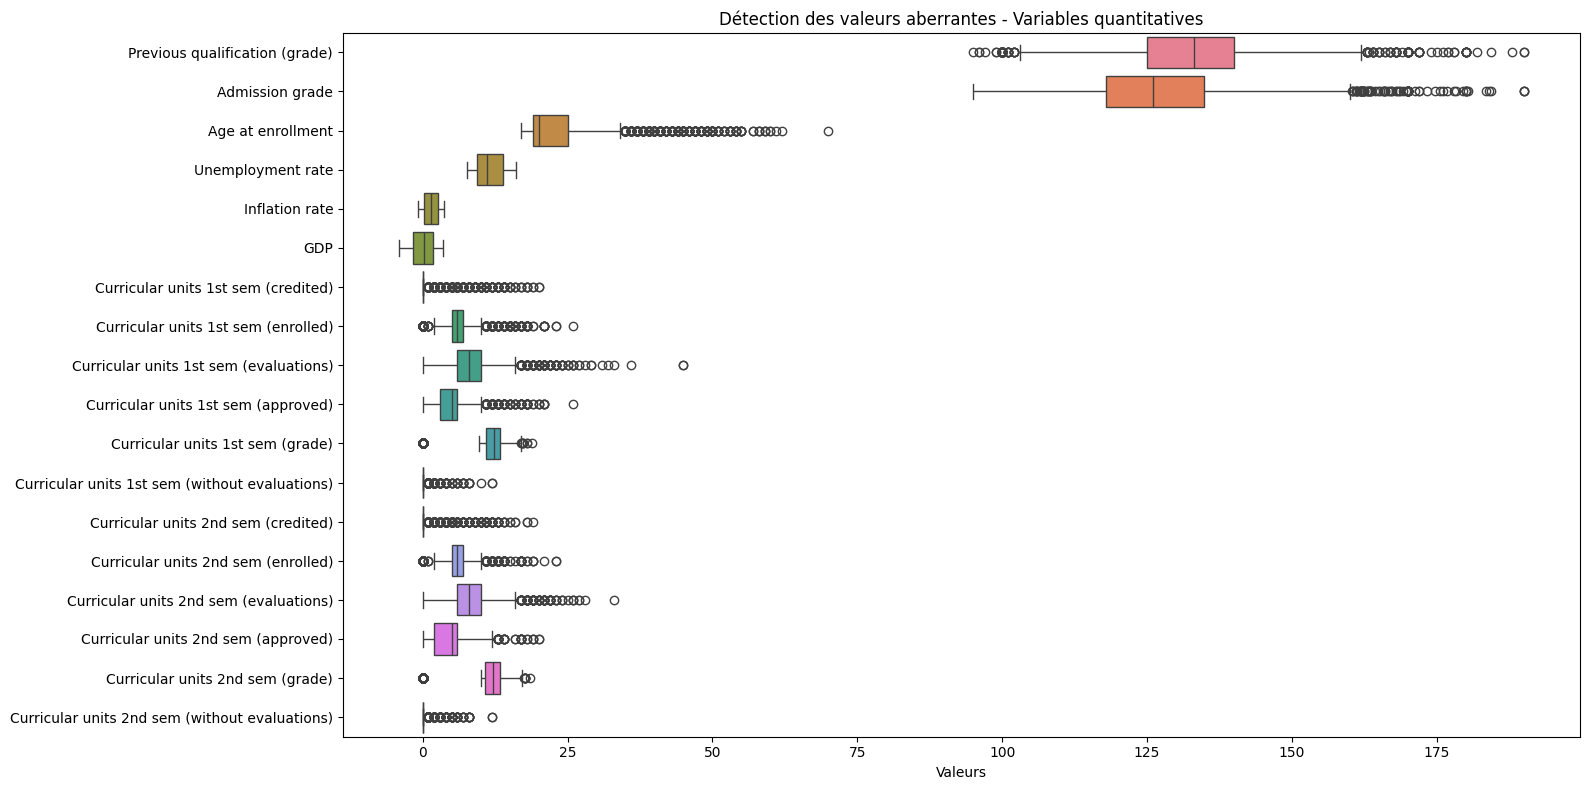

In [84]:
plt.figure(figsize=(16, 8))

sns.boxplot(data=df[numerical_cols], orient="h")

plt.title("Détection des valeurs aberrantes - Variables quantitatives")
plt.xlabel("Valeurs")
plt.tight_layout()
plt.show()

Visualisation des notes

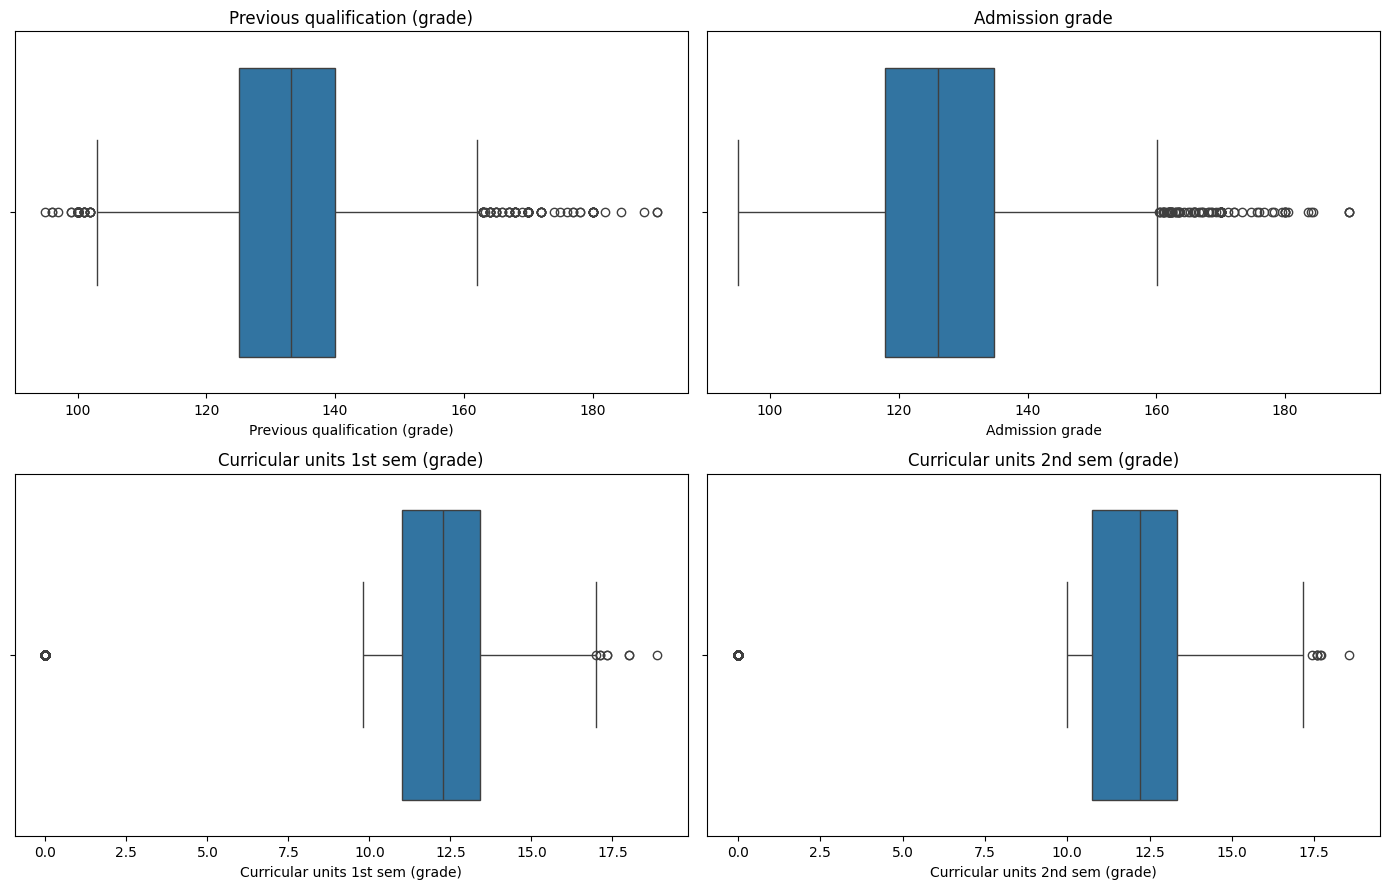

In [85]:
grade_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), grade_cols):

    sns.boxplot(x=df[col], ax=ax)

    ax.set_title(col)

plt.tight_layout()
plt.show()

## 6. Analyse des relations entre les variables

6.1 Matrice de corrélation

On étudie les corrélations entre les variables quantitatives.

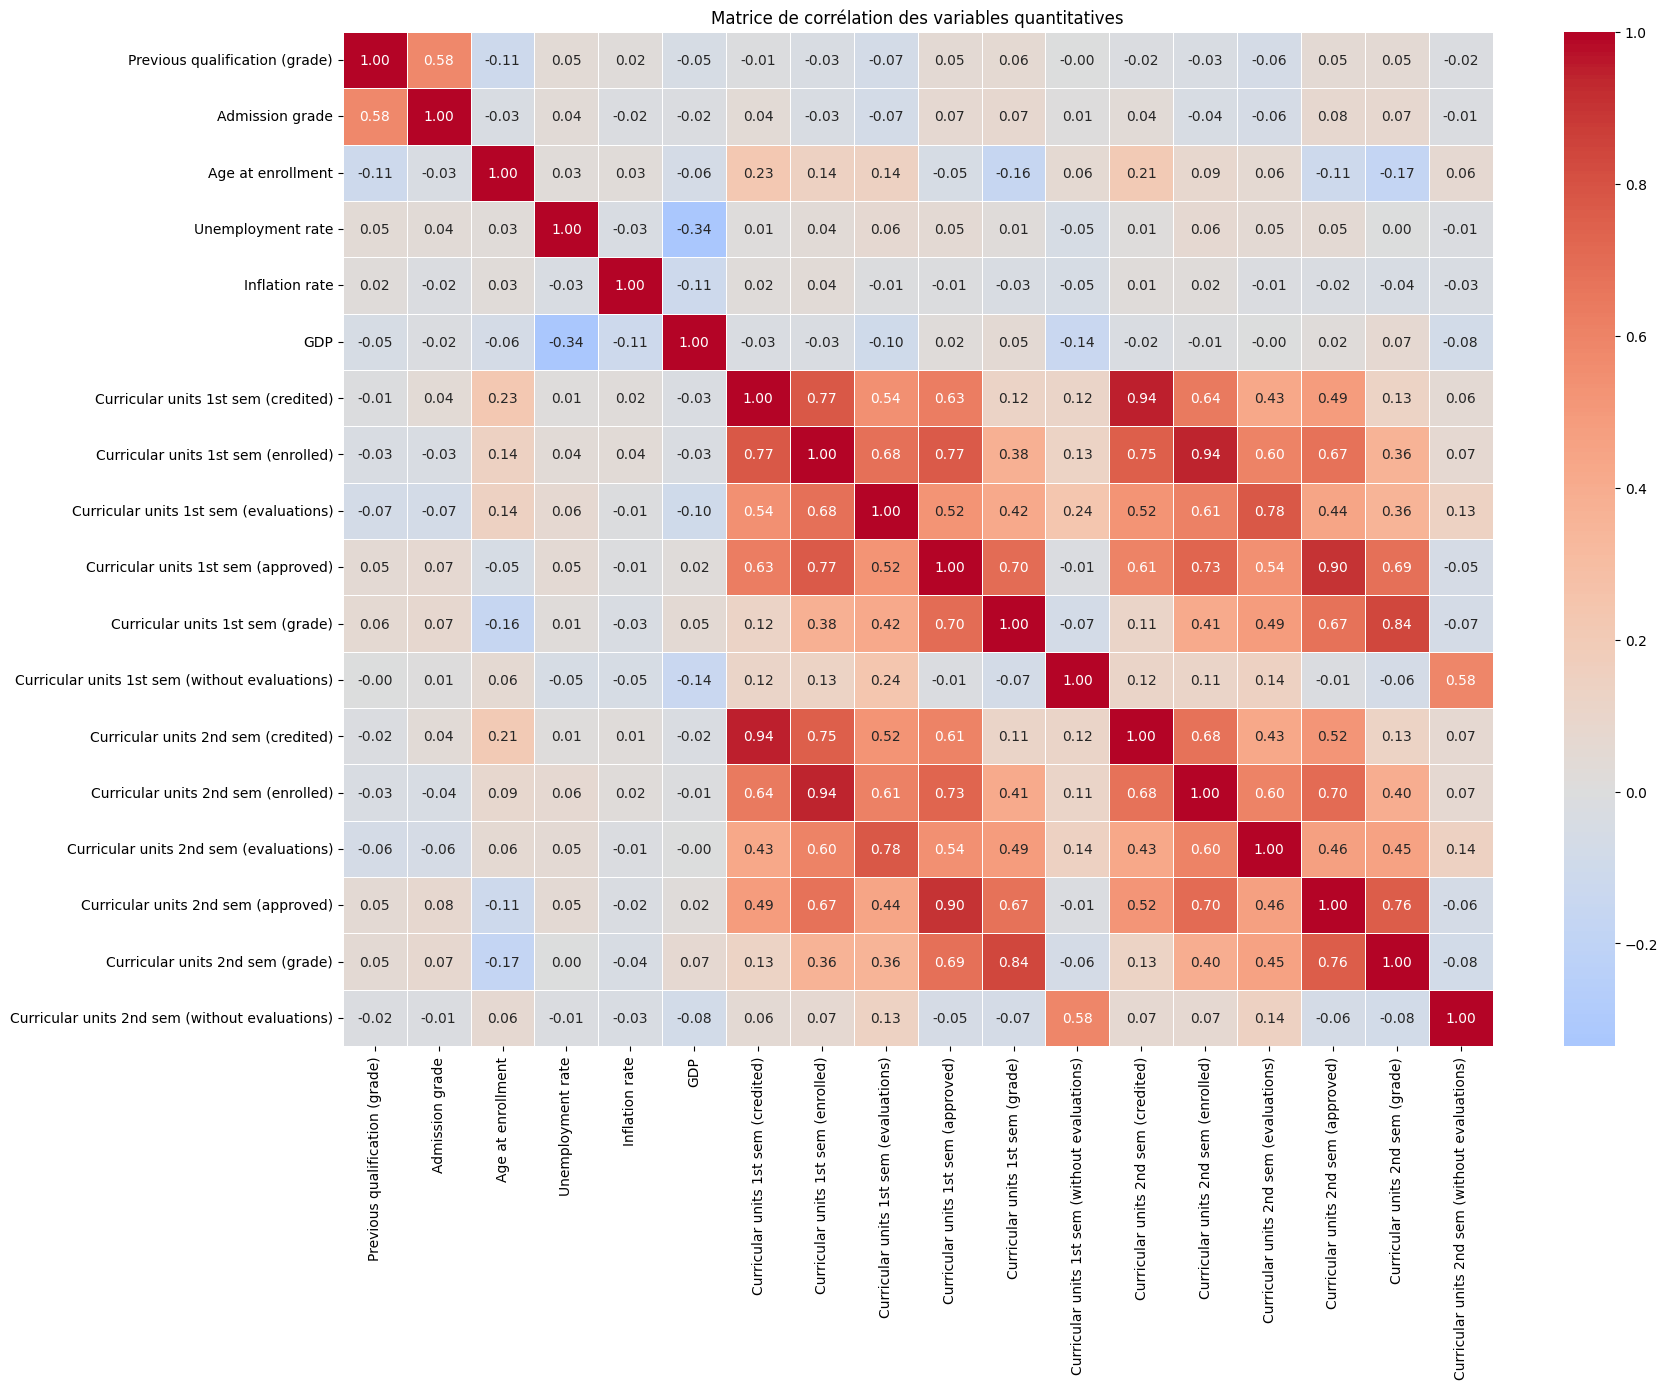

In [86]:
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matrice de corrélation des variables quantitatives")
plt.tight_layout()
plt.show()

6.2 Relation entre les notes et la variable cible

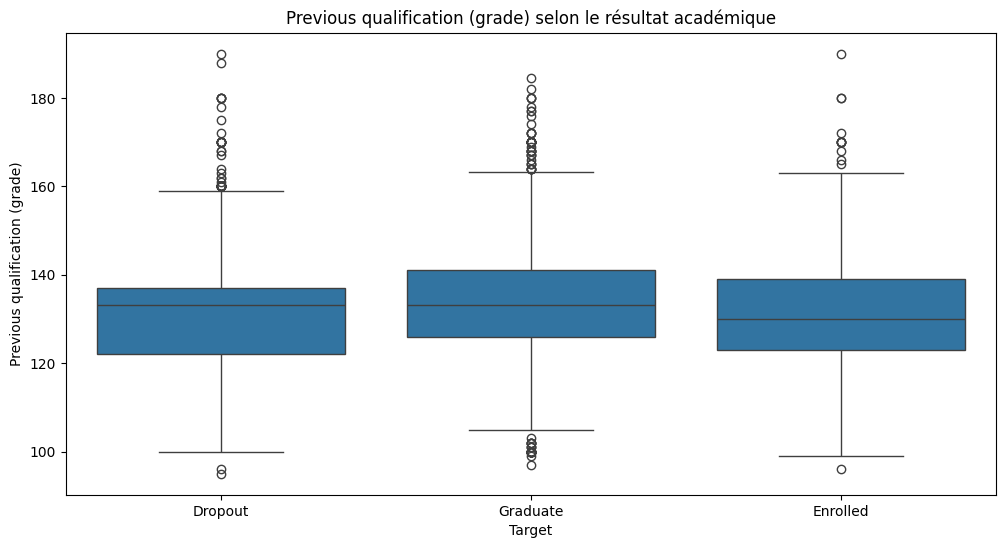

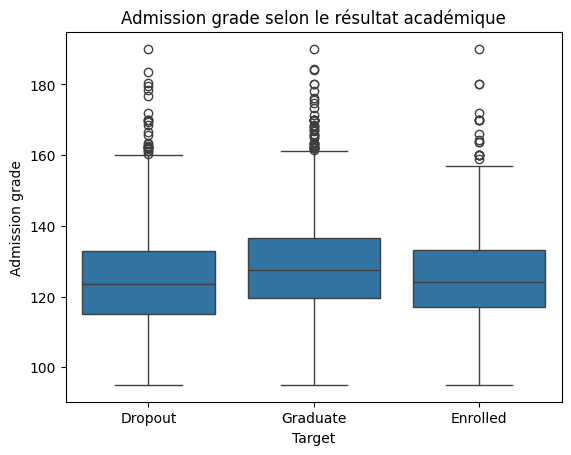

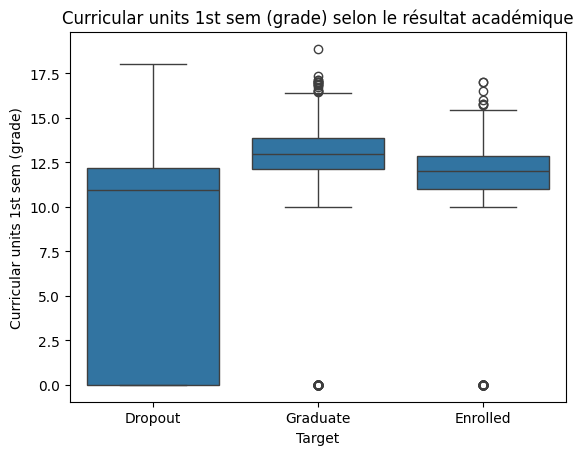

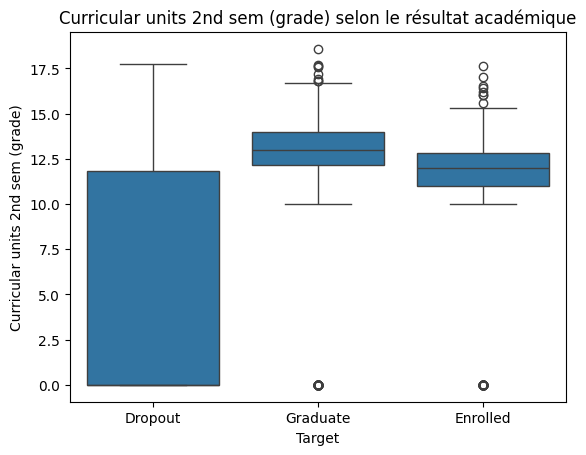

In [87]:
plt.figure(figsize=(12, 6))

for col in grade_cols:
    sns.boxplot(
        data=df,
        x="Target",
        y=col
    )
    plt.title(f"{col} selon le résultat académique")
    plt.show()

6.3 Comparaison des moyennes académiques selon Target

In [88]:
academic_grade_cols = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

grade_comparison = (
    df.groupby("Target")[academic_grade_cols]
    .mean()
    .round(2)
)

display(grade_comparison)

,Previous qualification (grade),Admission grade,Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
Target,,,,
Dropout,131.11,124.96,7.26,5.90
Enrolled,131.21,125.53,11.13,11.12
Graduate,134.08,128.79,12.64,12.70


6.4 Comparaison des variables académiques

In [89]:
academic_comparison = (
    df.groupby("Target")[academic_cols]
    .mean()
    .round(2)
)

display(academic_comparison)

,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations)
Target,,,,,,,,,,,,
Dropout,0.61,5.82,7.75,2.55,7.26,0.19,0.45,5.78,7.17,1.94,5.90,0.24
Enrolled,0.51,5.96,9.34,4.32,11.13,0.18,0.36,5.94,9.44,4.06,11.12,0.19
Graduate,0.85,6.67,8.28,6.23,12.64,0.09,0.67,6.63,8.14,6.18,12.70,0.08


## 7. Vérification de l'équilibre des classes

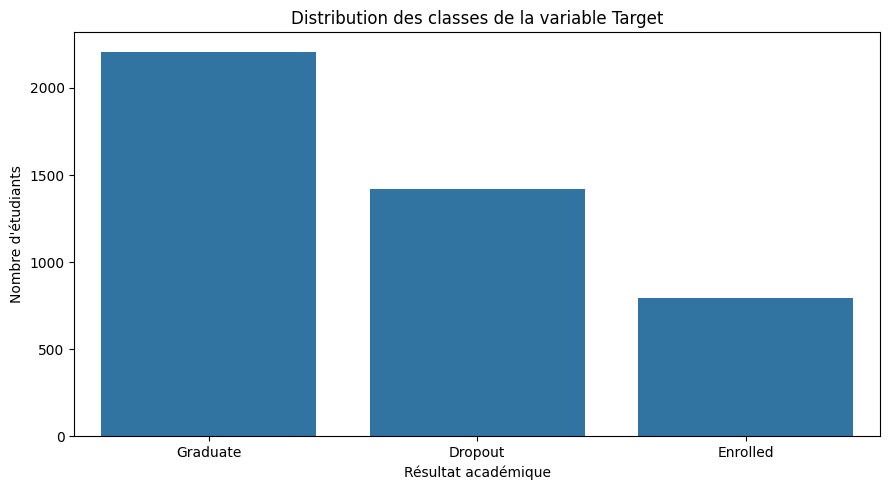

In [90]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Target",
    order=df["Target"].value_counts().index
)

plt.title("Distribution des classes de la variable Target")
plt.xlabel("Résultat académique")
plt.ylabel("Nombre d'étudiants")

plt.tight_layout()
plt.show()

Calcul des proportions :

In [91]:
class_distribution = pd.DataFrame({
    "Effectif": df["Target"].value_counts(),
    "Pourcentage": df["Target"].value_counts(normalize=True) * 100
})

display(class_distribution.round(2))

,Effectif,Pourcentage
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


## 8. Préparation des données pour le Machine Learning

8.1 Séparation entre X et y

In [92]:
# Variables explicatives
X = df.drop(columns=["Target"])

# Variable cible
y = df["Target"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (4424, 36)
Dimensions de y : (4424,)


8.2 Séparation Train/Test

In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensions X_train :", X_train.shape)
print("Dimensions X_test :", X_test.shape)

print("\nDimensions y_train :", y_train.shape)
print("Dimensions y_test :", y_test.shape)

Dimensions X_train : (3539, 36)
Dimensions X_test : (885, 36)

Dimensions y_train : (3539,)
Dimensions y_test : (885,)


In [94]:
print("Distribution originale :")
display(y.value_counts(normalize=True).round(3))

print("\nDistribution Train :")
display(y_train.value_counts(normalize=True).round(3))

print("\nDistribution Test :")
display(y_test.value_counts(normalize=True).round(3))

Distribution originale :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


Distribution Train :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


Distribution Test :


Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64

## 9. Encodage des variables catégorielles

In [95]:
# Encodage des variables catégorielles
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    dtype=int
)

# Aligner les colonnes de Test sur celles de Train
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Train après encodage :", X_train_encoded.shape)
print("Test après encodage :", X_test_encoded.shape)

Train après encodage : (3539, 251)
Test après encodage : (885, 251)


Normalisation avec StandardScaler

In [96]:
# Initialisation
scaler = StandardScaler()

# Apprentissage uniquement sur Train
X_train_encoded[numerical_cols] = scaler.fit_transform(
    X_train_encoded[numerical_cols]
)

# Application des mêmes paramètres sur Test
X_test_encoded[numerical_cols] = scaler.transform(
    X_test_encoded[numerical_cols]
)

print("Normalisation terminée.")

Normalisation terminée.


## Information Gain (IG)

L'Information Gain est une méthode de sélection des variables
basée sur la théorie de l'information.

Elle mesure la réduction de l'entropie de la variable cible
après avoir observé une variable explicative.

Une valeur élevée signifie que la variable apporte
une quantité importante d'information pour prédire Target.

Dans notre projet, cette méthode permet de classer les
variables selon leur capacité à distinguer les trois
résultats académiques : Dropout, Graduate et Enrolled.

Les scores sont calculés uniquement sur les données
d'entraînement afin d'éviter le Data Leakage.

In [97]:

def entropy(y):

    probabilities = y.value_counts(normalize=True)

    return -sum(
        p * log2(p)
        for p in probabilities
        if p > 0
    )


def information_gain_manual(X, y):

    initial_entropy = entropy(y)

    conditional_entropy = 0

    for value in X.unique():

        # Sélection des individus correspondant
        # à la modalité courante
        subset = y[X == value]

        # Poids du sous-ensemble
        weight = len(subset) / len(y)

        # Contribution à l'entropie conditionnelle
        conditional_entropy += (
            weight * entropy(subset)
        )

    information_gain = (
        initial_entropy - conditional_entropy
    )

    return information_gain

In [98]:
target_entropy = entropy(y_train)

print("Entropie de Target :", round(target_entropy, 4))

Entropie de Target : 1.4713


### Standardisation des variables numériques

Les variables quantitatives sont standardisées avant le calcul de
l'Information Gain.

Le scaler est ajusté uniquement sur les données d'entraînement.
Les données de test ne sont pas utilisées dans cette étape.

La standardisation permet de mettre les variables numériques sur
une échelle comparable.

In [99]:
# Copie du jeu d'entraînement original
X_train_ig = X_train.copy()

# Initialisation du scaler
scaler_ig = StandardScaler()

# Standardisation uniquement des variables numériques
X_train_ig[numerical_cols] = scaler_ig.fit_transform(
    X_train_ig[numerical_cols]
)

print("Standardisation pour l'Information Gain terminée.")

Standardisation pour l'Information Gain terminée.


### Discrétisation des variables numériques

L'Information Gain manuel utilisé ici fonctionne sur des modalités
discrètes.

Les variables numériques standardisées sont donc transformées en
10 intervalles à l'aide de la discrétisation par quantiles.

Chaque intervalle contient approximativement le même nombre
d'observations.

La discrétisation est réalisée uniquement sur les données d'entraînement.

In [100]:
def discretize_numeric(series, bins=10):

    return pd.qcut(
        series,
        q=bins,
        duplicates="drop"
    )

## Calculer l'Information Gain des 36 variables

In [101]:
# Liste pour stocker les résultats
ig_results = []

# ---------------------------------------------------------
# 1. VARIABLES CATEGORIELLES
# ---------------------------------------------------------

for col in categorical_cols:

    ig = information_gain_manual(
        X_train_ig[col],
        y_train
    )

    ig_results.append({
        "Feature": col,
        "Type": "Categorical",
        "Information Gain": ig
    })


# ---------------------------------------------------------
# 2. VARIABLES NUMERIQUES
# ---------------------------------------------------------

for col in numerical_cols:

    # Discrétisation après standardisation
    X_discrete = discretize_numeric(
        X_train_ig[col],
        bins=10
    )

    ig = information_gain_manual(
        X_discrete,
        y_train
    )

    ig_results.append({
        "Feature": col,
        "Type": "Numerical",
        "Information Gain": ig
    })


# ---------------------------------------------------------
# CREATION DU TABLEAU FINAL
# ---------------------------------------------------------

ig_df = pd.DataFrame(ig_results)

# Trier du plus important au moins important
ig_df = (
    ig_df
    .sort_values(
        by="Information Gain",
        ascending=False
    )
    .reset_index(drop=True)
)

# Arrondir pour l'affichage
ig_df["Information Gain"] = (
    ig_df["Information Gain"].round(6)
)

display(ig_df)

,Feature,Type,Information Gain
0,Curricular units 2nd sem (approved),Numerical,0.435417
1,Curricular units 1st sem (approved),Numerical,0.328521
2,Curricular units 2nd sem (grade),Numerical,0.302761
3,Curricular units 1st sem (grade),Numerical,0.221454
4,Tuition fees up to date,Categorical,0.133613
5,Curricular units 2nd sem (evaluations),Numerical,0.128839
6,Curricular units 1st sem (evaluations),Numerical,0.117961
7,Course,Categorical,0.097284
8,Application mode,Categorical,0.086693
9,Age at enrollment,Numerical,0.082147


## Visualisation des Information Gains

### Classement des variables selon l'Information Gain

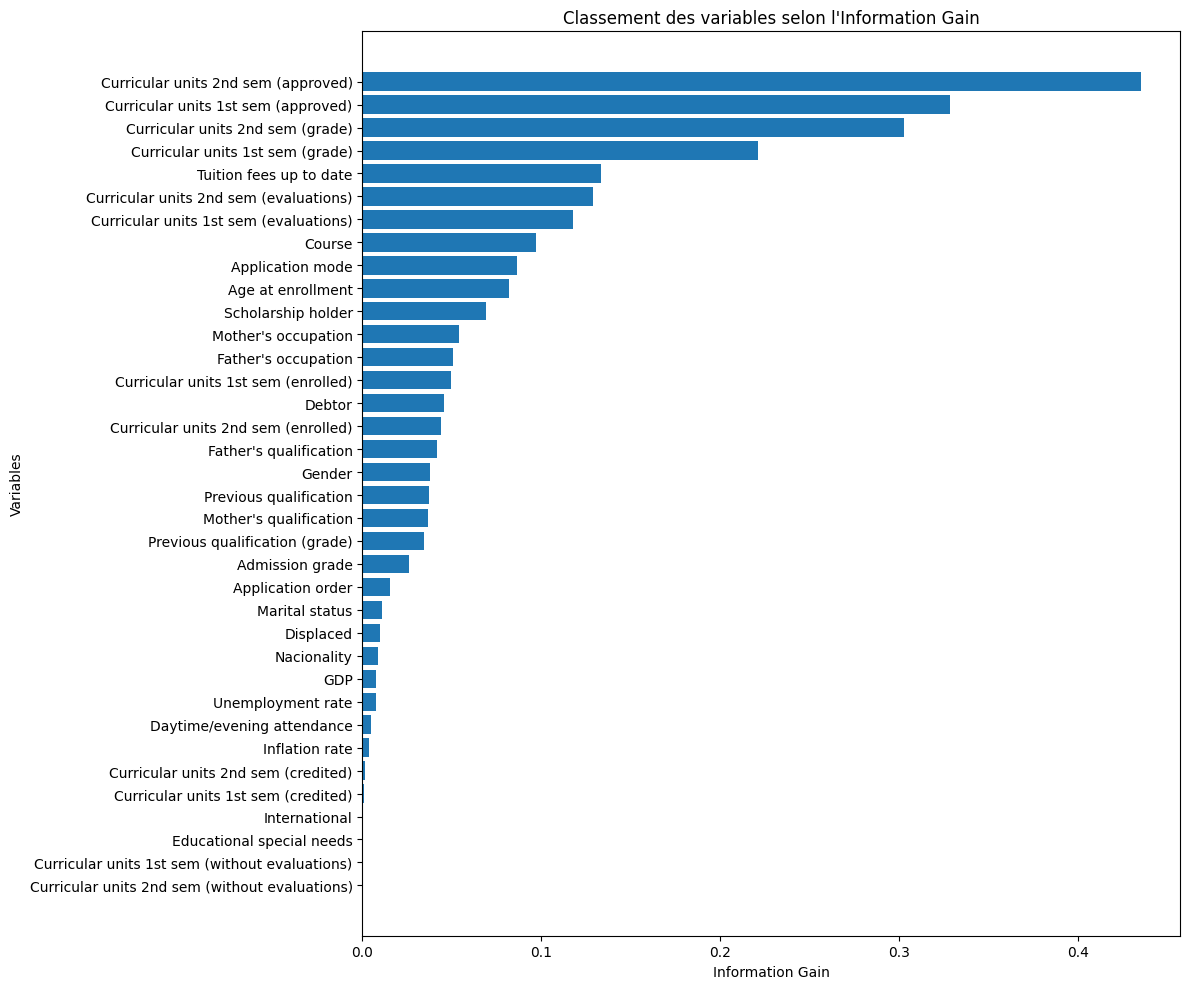

In [102]:
plt.figure(figsize=(12, 10))

plt.barh(
    ig_df["Feature"],
    ig_df["Information Gain"]
)

plt.xlabel("Information Gain")
plt.ylabel("Variables")
plt.title("Classement des variables selon l'Information Gain")

# Mettre la variable la plus importante en haut
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Affichage des meilleures variables

In [103]:
# ============================================================
# Sélection du nombre de variables
# ============================================================

# Valeurs de K que nous voulons tester
k_values = [5, 10, 15, 20, 25, 30, 36]

print("Nombre total de variables disponibles :", len(ig_df))
print("\nNombre de variables testées :")
for k in k_values:
    print(f"- Top {k}")

Nombre total de variables disponibles : 36

Nombre de variables testées :
- Top 5
- Top 10
- Top 15
- Top 20
- Top 25
- Top 30
- Top 36


In [104]:
# Affichage des variables sélectionnées pour chaque valeur de K

for k in k_values:
    print(f"\n{'='*50}")
    print(f"TOP {k} VARIABLES")
    print(f"{'='*50}")
    
    selected = ig_df.head(k)["Feature"].tolist()
    
    for i, feature in enumerate(selected, start=1):
        ig_value = ig_df.loc[ig_df["Feature"] == feature, "Information Gain"].values[0]
        print(f"{i:2d}. {feature:<50} IG = {ig_value:.6f}")


TOP 5 VARIABLES
 1. Curricular units 2nd sem (approved)                IG = 0.435417
 2. Curricular units 1st sem (approved)                IG = 0.328521
 3. Curricular units 2nd sem (grade)                   IG = 0.302761
 4. Curricular units 1st sem (grade)                   IG = 0.221454
 5. Tuition fees up to date                            IG = 0.133613

TOP 10 VARIABLES
 1. Curricular units 2nd sem (approved)                IG = 0.435417
 2. Curricular units 1st sem (approved)                IG = 0.328521
 3. Curricular units 2nd sem (grade)                   IG = 0.302761
 4. Curricular units 1st sem (grade)                   IG = 0.221454
 5. Tuition fees up to date                            IG = 0.133613
 6. Curricular units 2nd sem (evaluations)             IG = 0.128839
 7. Curricular units 1st sem (evaluations)             IG = 0.117961
 8. Course                                             IG = 0.097284
 9. Application mode                                   IG = 0.086693

Exportation des données

In [105]:
import joblib
import os

os.makedirs("outputs", exist_ok=True)

# Ajouter la variable cible
train_final = X_train_encoded.copy()
train_final["Target"] = y_train

test_final = X_test_encoded.copy()
test_final["Target"] = y_test

# Exporter
train_final.to_csv("outputs/train_processed.csv", index=False)
test_final.to_csv("outputs/test_processed.csv", index=False)

# Sauvegarder le scaler
joblib.dump(scaler, "outputs/scaler.pkl")

print("Exportation terminée !")

Exportation terminée !
